<a href="https://colab.research.google.com/github/marilynhruza-creator/Estadistica-/blob/main/MOD3_Teoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# =====================================================
# Comparativa de complejidad algorítmica
# Bubble Sort vs Timsort (sorted de Python)
# =====================================================

Tamaño	Bubble Sort	Timsort
100	0.000720	0.000016
500	0.020812	0.000078
1000	0.098501	0.000192
2000	0.460685	0.000410
4000	1.661167	0.000573
8000	No medido	0.001351


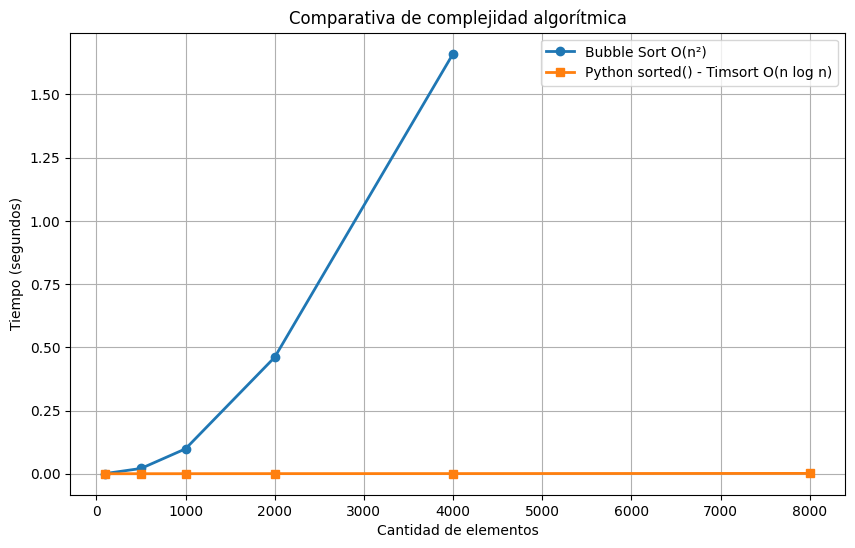

In [2]:


import random
import time
import matplotlib.pyplot as plt

# -----------------------------------------------------
# Implementación de Bubble Sort
# -----------------------------------------------------

def bubble_sort(lista):
    datos = lista.copy()
    n = len(datos)

    for i in range(n):
        for j in range(0, n - i - 1):
            if datos[j] > datos[j + 1]:
                datos[j], datos[j + 1] = datos[j + 1], datos[j]

    return datos

# -----------------------------------------------------
# Función para medir tiempos
# -----------------------------------------------------

def medir_tiempo(funcion, datos):

    inicio = time.perf_counter()

    funcion(datos)

    fin = time.perf_counter()

    return fin - inicio

# -----------------------------------------------------
# Tamaños de prueba
# -----------------------------------------------------

tamanos = [100, 500, 1000, 2000, 4000, 8000]

tiempo_bubble = []
tiempo_timsort = []

# -----------------------------------------------------
# Comparación
# -----------------------------------------------------

for n in tamanos:

    datos = [random.randint(1, 100000) for _ in range(n)]

    # Bubble Sort se vuelve muy lento para grandes tamaños
    if n <= 4000:
        tiempo_bubble.append(
            medir_tiempo(bubble_sort, datos)
        )
    else:
        tiempo_bubble.append(None)

    tiempo_timsort.append(
        medir_tiempo(sorted, datos)
    )

# -----------------------------------------------------
# Resultados numéricos
# -----------------------------------------------------

print("Tamaño\tBubble Sort\tTimsort")

for i in range(len(tamanos)):

    bubble = (
        f"{tiempo_bubble[i]:.6f}"
        if tiempo_bubble[i] is not None
        else "No medido"
    )

    print(
        f"{tamanos[i]}\t{bubble}\t{tiempo_timsort[i]:.6f}"
    )

# -----------------------------------------------------
# Gráfico comparativo
# -----------------------------------------------------

plt.figure(figsize=(10,6))

# Bubble Sort
x_bubble = []
y_bubble = []

for i in range(len(tamanos)):
    if tiempo_bubble[i] is not None:
        x_bubble.append(tamanos[i])
        y_bubble.append(tiempo_bubble[i])

plt.plot(
    x_bubble,
    y_bubble,
    marker='o',
    linewidth=2,
    label='Bubble Sort O(n²)'
)

# Timsort
plt.plot(
    tamanos,
    tiempo_timsort,
    marker='s',
    linewidth=2,
    label='Python sorted() - Timsort O(n log n)'
)

plt.xlabel("Cantidad de elementos")
plt.ylabel("Tiempo (segundos)")
plt.title("Comparativa de complejidad algorítmica")
plt.grid(True)
plt.legend()

plt.show()